# Voyage Analytics — Educational Gender-Label Classification
**Project type:** Classification  
**Contribution:** Individual  
**Author:** techysuman27

# Project Summary
Test whether age and company contain predictive information about recorded labels. The undocumented label none is retained, while personal names and identifier code are excluded. Results are an educational benchmark and must not be treated as identity inference.

This notebook provides the assessed modeling narrative. The shared package implements repeatable training and preprocessing used by Flask and Airflow as well. MLflow captures the experiment; Docker, Kubernetes and Jenkins belong to the accompanying repository. Measured outputs below come from this dataset and must not be described as real-world travel-market performance.

# GitHub Link
https://github.com/techysuman27/MLOps-Travel-App

# Problem Statement
Test whether age and company contain predictive information about recorded labels. The undocumented label none is retained, while personal names and identifier code are excluded. Results are an educational benchmark and must not be treated as identity inference.

# General Guidelines
Follow the supplied template's eight main sections. This original notebook contains fifteen training-only visualizations, with reasons, measured observations and business implications. The test partition is reserved for final evaluation. Run all cells in order. The initial bootstrap may require network access in Colab.

In [1]:
import os, sys, subprocess
from pathlib import Path
os.environ['OMP_NUM_THREADS'] = '4'
os.environ['MLFLOW_DISABLE_AGENT_HINT'] = '1'
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    root = Path('/content/MLOps-Travel-App')
    if not root.exists():
        subprocess.run(['git', 'clone', 'https://github.com/techysuman27/MLOps-Travel-App.git', str(root)], check=True)
    os.chdir(root)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', 'requirements.txt'], check=True)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '--no-deps', '.'], check=True)
else:
    root = Path.cwd()
    if root.name == 'notebooks': root = root.parent
    os.chdir(root)
    sys.path.insert(0, str(root / 'src'))
if not Path('data/raw/flights.csv').exists():
    subprocess.run([sys.executable, 'scripts/download_data.py'], check=True)
TASK = 'classification'
print('Repository:', root)

Repository: C:\Users\dataw\OneDrive\Desktop\Almabetter Master Project


## 1. Know Your Data
### Import Libraries and Dataset Loading

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image
from io import BytesIO
from sklearn.model_selection import train_test_split
from voyage.data import load_data, chronological_split, sha256
from voyage.exploration import draw_chart
from voyage.training import run_training
from voyage.artifacts import load_bundle, promote
frames = load_data('data/raw')
df = frames['users' if TASK == 'classification' else TASK]
print('Rows and columns:', df.shape)
display(df.drop(columns=['name'], errors='ignore').head())
display(pd.DataFrame({'dtype': df.dtypes.astype(str), 'missing': df.isna().sum(), 'unique': df.nunique()}))
print('Exact duplicates:', df.duplicated().sum())

Rows and columns: (1340, 5)


,code,company,gender,age
0,0,4You,male,21
1,1,4You,male,37
2,2,4You,female,48
3,3,4You,female,23
4,4,4You,female,44


,dtype,missing,unique
code,int64,0,1340
company,str,0,5
name,str,0,1338
gender,str,0,3
age,int64,0,45


Exact duplicates: 0


### What did we learn about the dataset?
Validation checks the required columns, numeric values, dates and user references. No empty fields or exact duplicate rows were found in the initial source audit. This does not establish representativeness or real-world validity. A travel/user pair has two flight legs; hotel totals must not be summed after an unrestricted flight join.

## 2. Understanding Your Variables

In [3]:
descriptions = {
    'travelCode': 'Trip identifier; grouping and linkage only', 'userCode': 'User reference; history and linkage only',
    'code': 'User identifier; excluded from classification features', 'from': 'Recorded origin', 'to': 'Recorded destination',
    'flightType': 'Recorded cabin category', 'price': 'Flight price or hotel nightly price, according to table',
    'time': 'Recorded flight duration', 'distance': 'Recorded flight distance; units unverified',
    'agency': 'Recorded agency', 'date': 'Recorded travel/booking date', 'name': 'User name or hotel name, according to table',
    'place': 'Hotel destination', 'days': 'Stay duration', 'total': 'Nightly price times stay duration',
    'company': 'Associated company', 'gender': 'Source label: male, female, none; none is undocumented', 'age': 'Recorded user age'
}
display(pd.DataFrame({'variable': df.columns, 'meaning': [descriptions[c] for c in df.columns]}))

,variable,meaning
0,code,User identifier; excluded from classification ...
1,company,Associated company
2,name,"User name or hotel name, according to table"
3,gender,"Source label: male, female, none; none is undo..."
4,age,Recorded user age


## 3. Data Wrangling

In [4]:
if TASK == 'classification':
    train, rest = train_test_split(df, test_size=.30, stratify=df.gender, random_state=42)
    valid, test = train_test_split(rest, test_size=.5, stratify=rest.gender, random_state=42)
    split = {'train': len(train), 'validation': len(valid), 'test': len(test)}
    assert set(train.code).isdisjoint(test.code)
else:
    train, valid, test, split = chronological_split(df, group_trips=TASK == 'flights')
    assert train.date.max() < valid.date.min() < test.date.min()
display(split)
eda = train.copy()

{'train': 938, 'validation': 201, 'test': 201}

### Manipulations and reasoning
Source dates are parsed explicitly. Numerical contract violations stop execution instead of being silently filled. There is no need to impute this complete source snapshot. Exploration below uses only the training partition. Flight trips crossing time boundaries are purged. For users, stratification preserves label representation while keeping each user in one partition. For hotels, future interactions remain held out and repeat bookings stay eligible.

## 4. Data Visualization, Storytelling and Experimenting with Charts

### Chart 1

**Why this chart?** Check the support for every source label, including none.

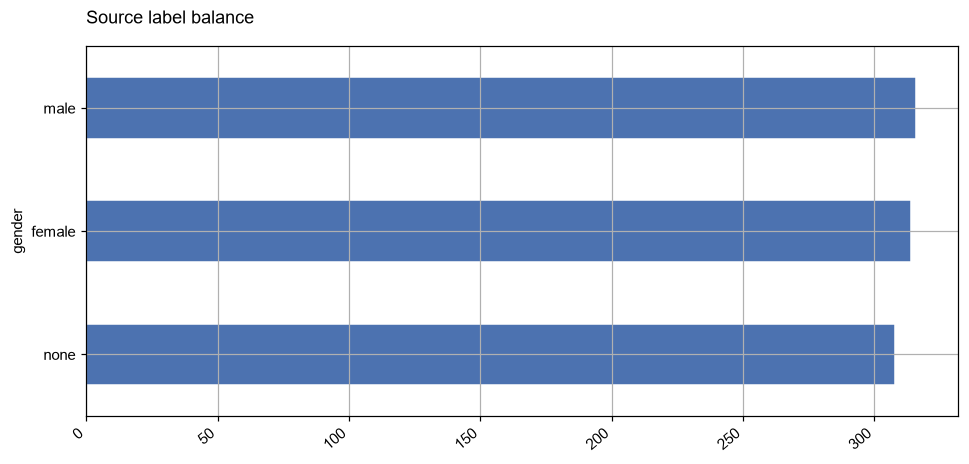

Observed insight: male has the largest count (316) in the training partition.


In [5]:
figure, observed_insight = draw_chart(TASK, 0, eda)
image_buffer = BytesIO()
figure.savefig(image_buffer, format='png', dpi=110, bbox_inches='tight')
display(Image(data=image_buffer.getvalue()))
plt.close(figure)
print('Observed insight:', observed_insight)

**Business implication:** Keep all documented source categories in evaluation; none has no established identity meaning.

### Chart 2

**Why this chart?** Inspect age coverage and spread.

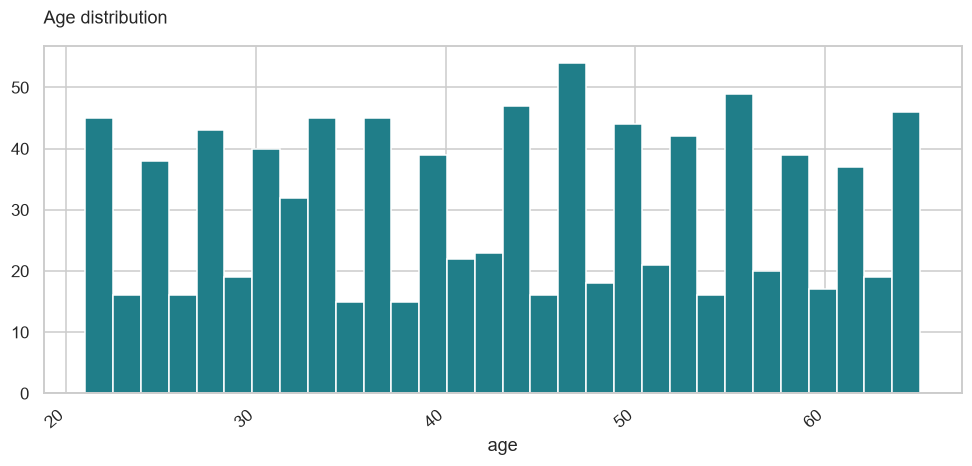

Observed insight: age: median=43.00; 10th–90th percentile=25.00–61.00.


In [6]:
figure, observed_insight = draw_chart(TASK, 1, eda)
image_buffer = BytesIO()
figure.savefig(image_buffer, format='png', dpi=110, bbox_inches='tight')
display(Image(data=image_buffer.getvalue()))
plt.close(figure)
print('Observed insight:', observed_insight)

**Business implication:** Avoid extrapolating beyond the observed age range; age is a limited feature for this educational benchmark.

### Chart 3

**Why this chart?** Measure company representation.

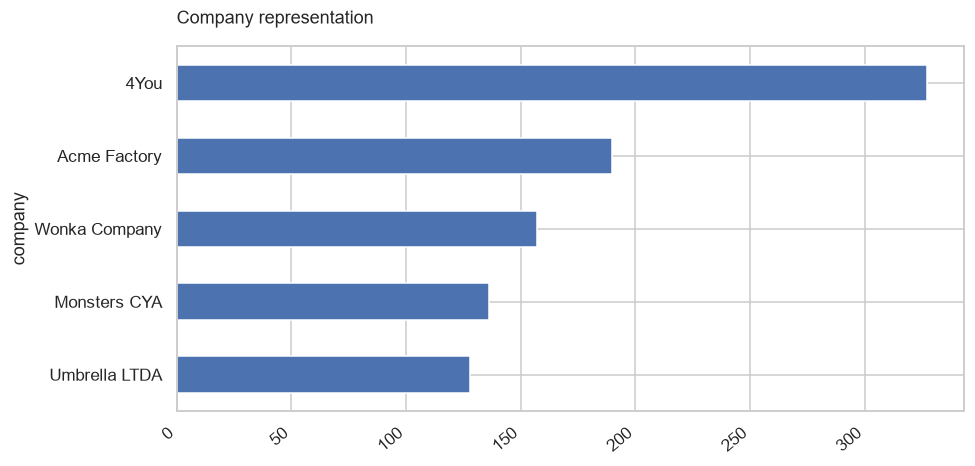

Observed insight: 4You has the largest count (327) in the training partition.


In [7]:
figure, observed_insight = draw_chart(TASK, 2, eda)
image_buffer = BytesIO()
figure.savefig(image_buffer, format='png', dpi=110, bbox_inches='tight')
display(Image(data=image_buffer.getvalue()))
plt.close(figure)
print('Observed insight:', observed_insight)

**Business implication:** A heavily represented company could dominate aggregate metrics; inspect company-level counts before interpreting performance.

### Chart 4

**Why this chart?** Compare age distributions across source labels.

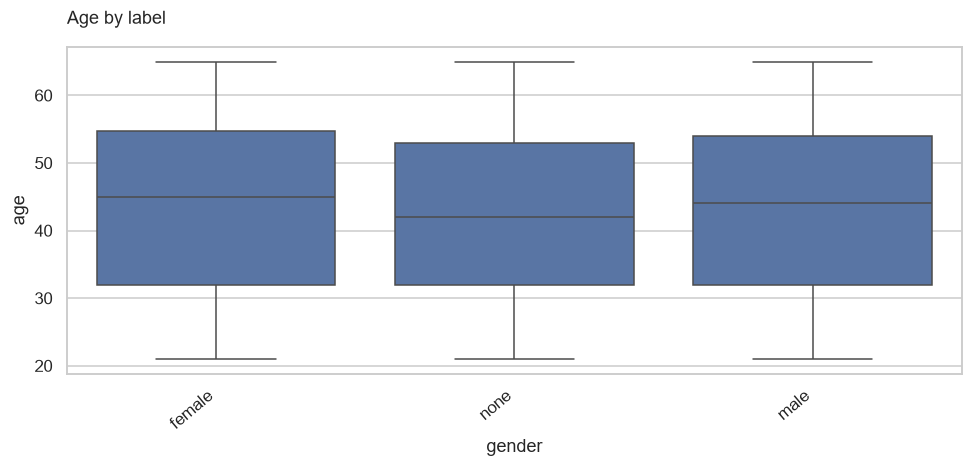

Observed insight: Median age ranges from 42.00 to 45.00 across gender groups. Differences do not establish causation.


In [8]:
figure, observed_insight = draw_chart(TASK, 3, eda)
image_buffer = BytesIO()
figure.savefig(image_buffer, format='png', dpi=110, bbox_inches='tight')
display(Image(data=image_buffer.getvalue()))
plt.close(figure)
print('Observed insight:', observed_insight)

**Business implication:** Strong overlap would limit simple age-based separation; confirm any apparent differences using held-out macro F1.

### Chart 5

**Why this chart?** Compare within-company label proportions.

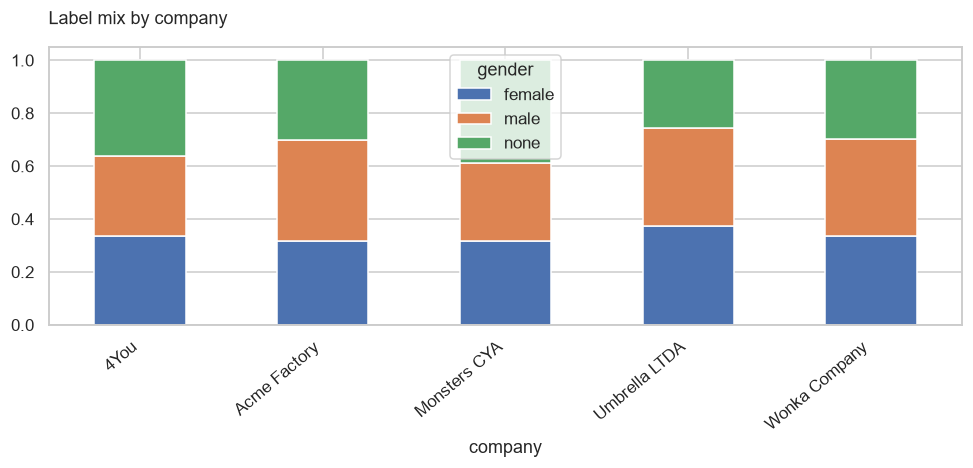

Observed insight: Group proportions show representation in the training sample; they are not evidence of a reliable identity classifier.


In [9]:
figure, observed_insight = draw_chart(TASK, 4, eda)
image_buffer = BytesIO()
figure.savefig(image_buffer, format='png', dpi=110, bbox_inches='tight')
display(Image(data=image_buffer.getvalue()))
plt.close(figure)
print('Observed insight:', observed_insight)

**Business implication:** Company may be a dataset-specific proxy. These proportions do not justify decisions about an individual.

### Chart 6

**Why this chart?** Compare age distributions across companies.

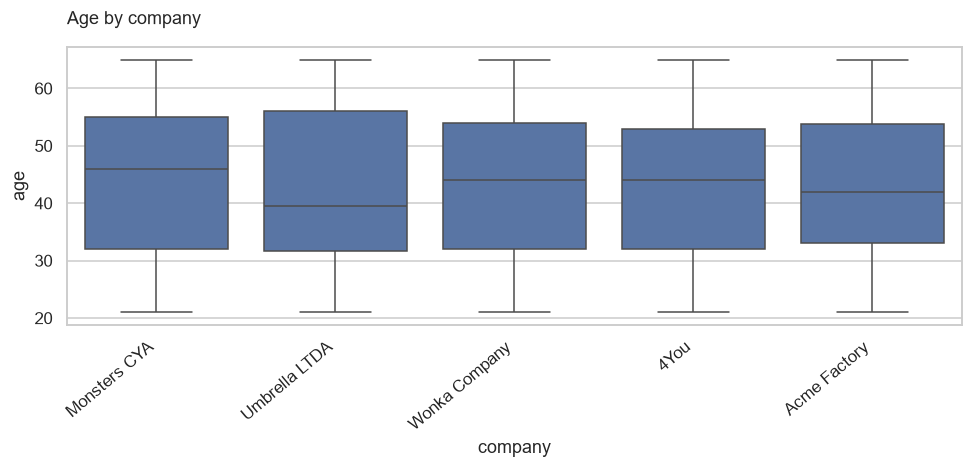

Observed insight: Median age ranges from 39.50 to 46.00 across company groups. Differences do not establish causation.


In [10]:
figure, observed_insight = draw_chart(TASK, 5, eda)
image_buffer = BytesIO()
figure.savefig(image_buffer, format='png', dpi=110, bbox_inches='tight')
display(Image(data=image_buffer.getvalue()))
plt.close(figure)
print('Observed insight:', observed_insight)

**Business implication:** Age and company composition may be related; avoid interpreting either as an independent cause of a label.

### Chart 7

**Why this chart?** Compare label proportions across age bands.

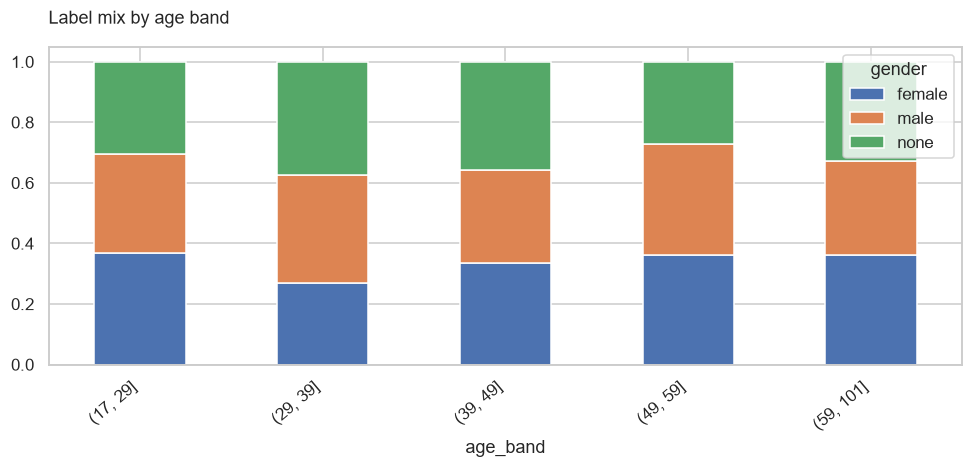

Observed insight: Group proportions show representation in the training sample; they are not evidence of a reliable identity classifier.


In [11]:
figure, observed_insight = draw_chart(TASK, 6, eda)
image_buffer = BytesIO()
figure.savefig(image_buffer, format='png', dpi=110, bbox_inches='tight')
display(Image(data=image_buffer.getvalue()))
plt.close(figure)
print('Observed insight:', observed_insight)

**Business implication:** Binning can reveal coverage gaps but also hide within-band variation; use original age in the fitted pipeline.

### Chart 8

**Why this chart?** Compare average ages across companies.

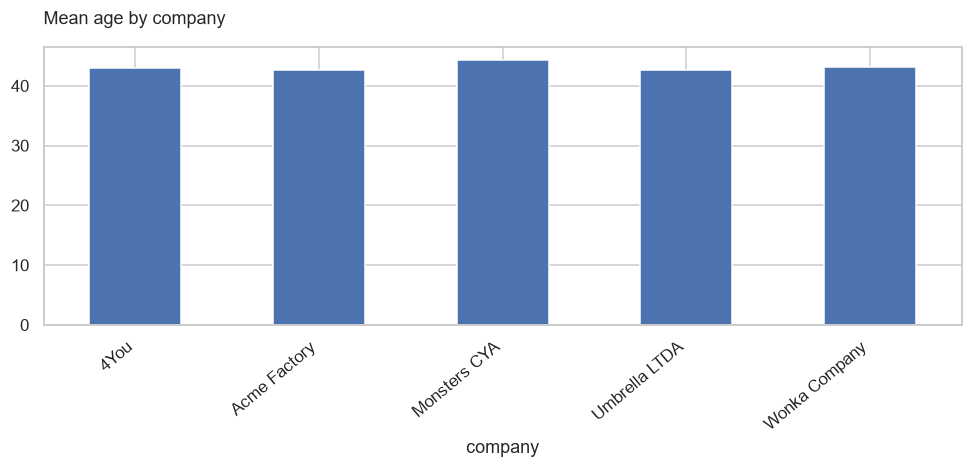

Observed insight: Mean age ranges from 42.55 to 44.26; group sample sizes must also be considered.


In [12]:
figure, observed_insight = draw_chart(TASK, 7, eda)
image_buffer = BytesIO()
figure.savefig(image_buffer, format='png', dpi=110, bbox_inches='tight')
display(Image(data=image_buffer.getvalue()))
plt.close(figure)
print('Observed insight:', observed_insight)

**Business implication:** Mean differences describe sample composition and do not establish predictive usefulness.

### Chart 9

**Why this chart?** Compare median ages across labels.

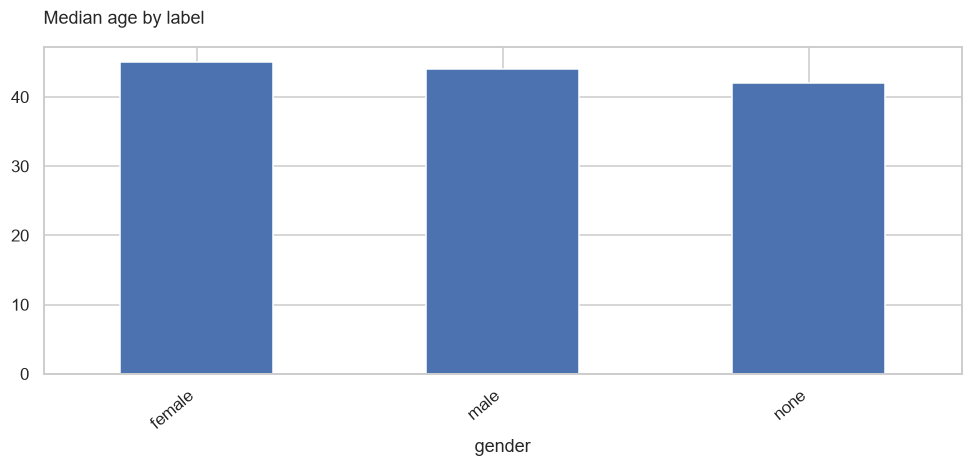

Observed insight: Median age ranges from 42.00 to 45.00; group sample sizes must also be considered.


In [13]:
figure, observed_insight = draw_chart(TASK, 8, eda)
image_buffer = BytesIO()
figure.savefig(image_buffer, format='png', dpi=110, bbox_inches='tight')
display(Image(data=image_buffer.getvalue()))
plt.close(figure)
print('Observed insight:', observed_insight)

**Business implication:** Similar medians support checking a weak-signal baseline instead of assuming that classification must work well.

### Chart 10

**Why this chart?** Overlay age distributions for the source labels.

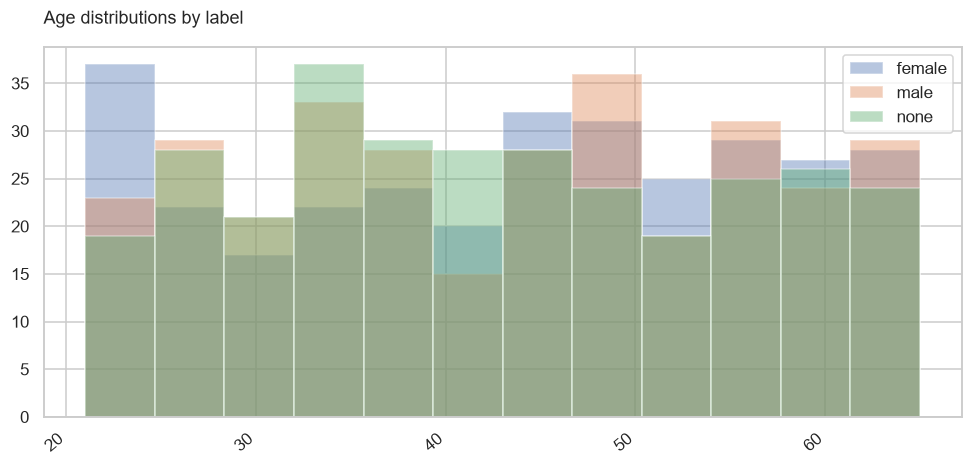

Observed insight: Overlapping age distributions limit the usefulness of a single age-based rule; confirm this with held-out metrics.


In [14]:
figure, observed_insight = draw_chart(TASK, 9, eda)
image_buffer = BytesIO()
figure.savefig(image_buffer, format='png', dpi=110, bbox_inches='tight')
display(Image(data=image_buffer.getvalue()))
plt.close(figure)
print('Observed insight:', observed_insight)

**Business implication:** Overlapping distributions explain why an age threshold may fail; retain uncertainty and baseline comparisons.

### Chart 11

**Why this chart?** Inspect company-by-label sample sizes.

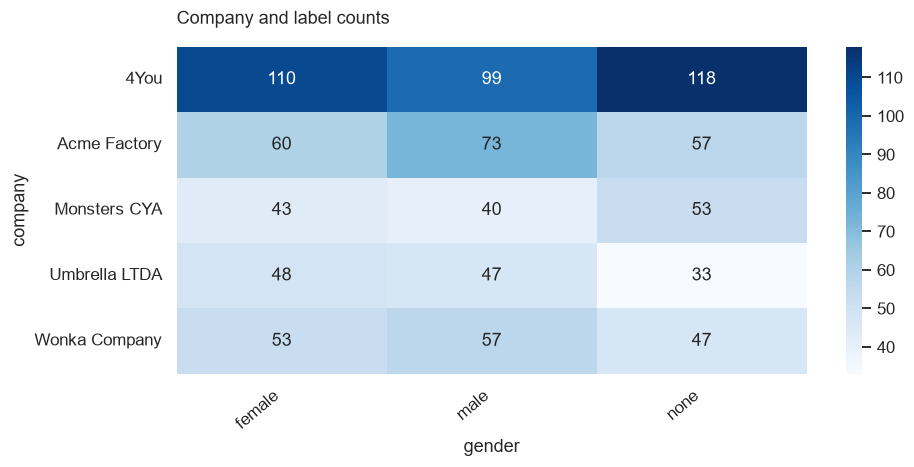

Observed insight: Counts identify small company/label subgroups where aggregate accuracy could conceal poor performance.


In [15]:
figure, observed_insight = draw_chart(TASK, 10, eda)
image_buffer = BytesIO()
figure.savefig(image_buffer, format='png', dpi=110, bbox_inches='tight')
display(Image(data=image_buffer.getvalue()))
plt.close(figure)
print('Observed insight:', observed_insight)

**Business implication:** Small cells make per-group estimates unstable; aggregate accuracy should not conceal sparse subgroup evidence.

### Chart 12

**Why this chart?** Compare age standard deviations across companies.

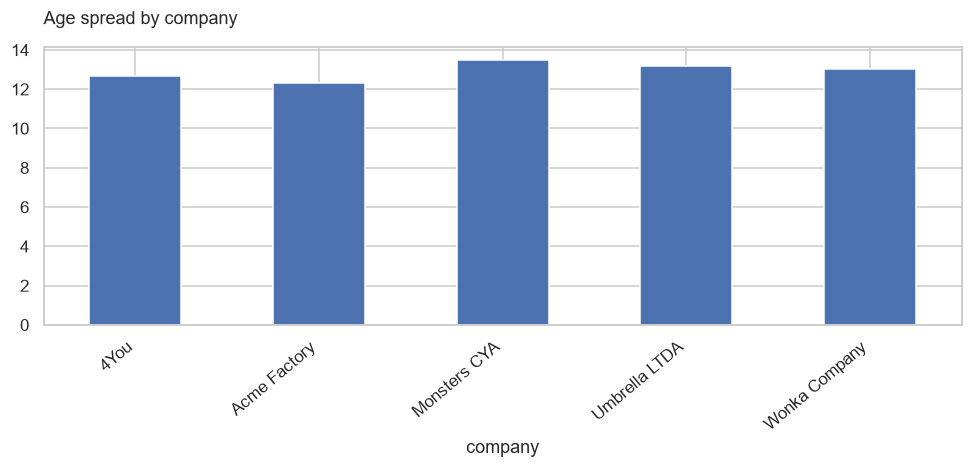

Observed insight: Std age ranges from 12.32 to 13.47; group sample sizes must also be considered.


In [16]:
figure, observed_insight = draw_chart(TASK, 11, eda)
image_buffer = BytesIO()
figure.savefig(image_buffer, format='png', dpi=110, bbox_inches='tight')
display(Image(data=image_buffer.getvalue()))
plt.close(figure)
print('Observed insight:', observed_insight)

**Business implication:** Different age spreads affect feature coverage, even when company means look similar.

### Chart 13

**Why this chart?** Measure the share of users younger than 30 in each company.

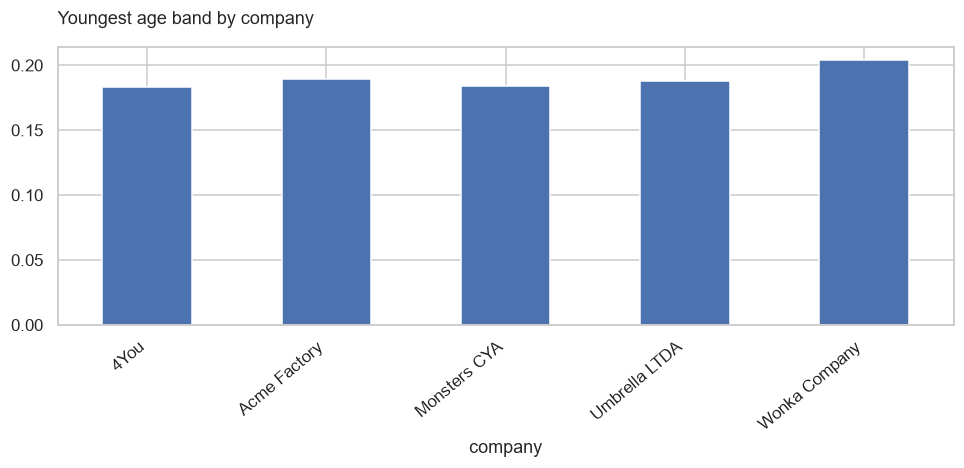

Observed insight: The selected age-band share ranges from 18.3% to 20.4%; company composition may act as a proxy and requires cautious interpretation.


In [17]:
figure, observed_insight = draw_chart(TASK, 12, eda)
image_buffer = BytesIO()
figure.savefig(image_buffer, format='png', dpi=110, bbox_inches='tight')
display(Image(data=image_buffer.getvalue()))
plt.close(figure)
print('Observed insight:', observed_insight)

**Business implication:** This describes company composition only; the threshold is exploratory and is not a classification rule.

### Chart 14

**Why this chart?** Measure the share of users aged 60 or above in each company.

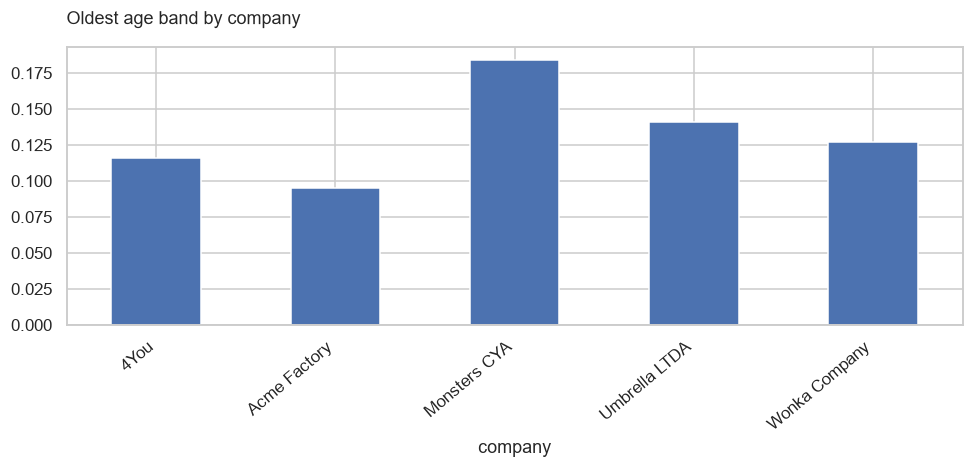

Observed insight: The selected age-band share ranges from 9.5% to 18.4%; company composition may act as a proxy and requires cautious interpretation.


In [18]:
figure, observed_insight = draw_chart(TASK, 13, eda)
image_buffer = BytesIO()
figure.savefig(image_buffer, format='png', dpi=110, bbox_inches='tight')
display(Image(data=image_buffer.getvalue()))
plt.close(figure)
print('Observed insight:', observed_insight)

**Business implication:** Sparse older age groups limit conclusions about generalization for those users.

### Chart 15

**Why this chart?** Reverse the normalization to show company representation within each label.

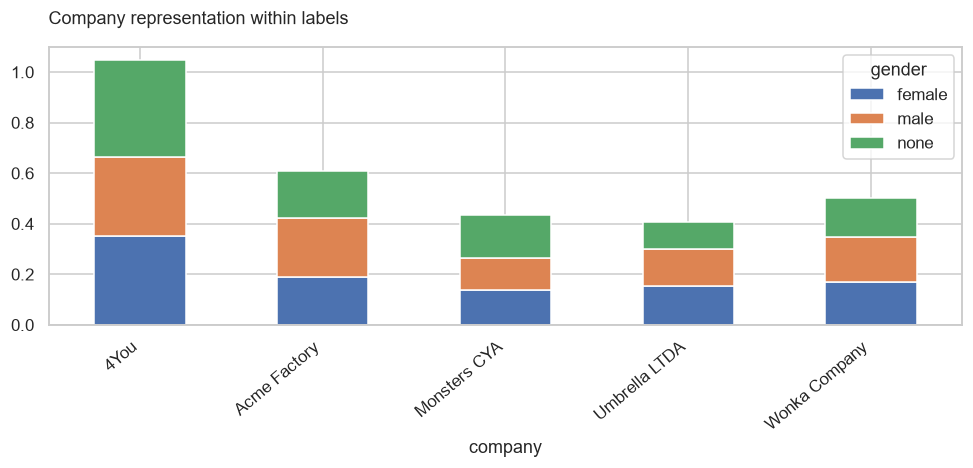

Observed insight: Group proportions show representation in the training sample; they are not evidence of a reliable identity classifier.


In [19]:
figure, observed_insight = draw_chart(TASK, 14, eda)
image_buffer = BytesIO()
figure.savefig(image_buffer, format='png', dpi=110, bbox_inches='tight')
display(Image(data=image_buffer.getvalue()))
plt.close(figure)
print('Observed insight:', observed_insight)

**Business implication:** The denominator changes the question: company composition within a label differs from label probability within a company.

## 5. Hypothesis Testing
These are exploratory checks on training data only, using three comparisons and a Bonferroni significance level of 0.05/3. Statistical association does not establish practical predictive value. Flight/hotel records repeat users and trips, so the tests use one observation per user to reduce within-user dependence; remaining observational confounding limits interpretation.

In [20]:
from scipy.stats import kruskal, chi2_contingency, spearmanr
independent = eda.drop_duplicates('code' if TASK == 'classification' else 'userCode')
tests = []
if TASK == 'flights':
    for category in ['flightType', 'agency']:
        groups = [group.price.to_numpy() for _, group in independent.groupby(category)]
        statistic, p = kruskal(*groups)
        tests.append((f'H0: price distributions are equal across {category}', statistic, p))
    statistic, p = spearmanr(independent.distance, independent.price)
    tests.append(('H0: distance and price have zero rank association', statistic, p))
elif TASK == 'classification':
    statistic, p, dof, expected = chi2_contingency(pd.crosstab(independent.company, independent.gender))
    tests.append(('H0: company and source label are independent', statistic, p))
    print('Minimum expected count for company/label chi-square:', expected.min())
    statistic, p = kruskal(*[group.age.to_numpy() for _, group in independent.groupby('gender')])
    tests.append(('H0: age distributions are equal across labels', statistic, p))
    statistic, p = kruskal(*[group.age.to_numpy() for _, group in independent.groupby('company')])
    tests.append(('H0: age distributions are equal across companies', statistic, p))
else:
    statistic, p = kruskal(*[group.days.to_numpy() for _, group in independent.groupby('place')])
    tests.append(('H0: stay distributions are equal across destinations', statistic, p))
    statistic, p = spearmanr(independent.days, independent.total)
    tests.append(('H0: stay duration and total have zero rank association', statistic, p))
    statistic, p = spearmanr(independent.price, independent.days)
    tests.append(('H0: nightly price and duration have zero rank association', statistic, p))
hypothesis_results = pd.DataFrame(tests, columns=['null_hypothesis', 'statistic', 'p_value'])
hypothesis_results['decision'] = np.where(hypothesis_results.p_value < .05 / 3, 'Reject H0 (exploratory)', 'Do not reject H0')
display(hypothesis_results)

Minimum expected count for company/label chi-square: 42.02985074626866


,null_hypothesis,statistic,p_value,decision
0,H0: company and source label are independent,10.188416,0.252050,Do not reject H0
1,H0: age distributions are equal across labels,0.736433,0.691967,Do not reject H0
2,H0: age distributions are equal across companies,1.563714,0.815299,Do not reject H0


### Test selection and limitations
Kruskal–Wallis compares group distributions without assuming normality; unequal distribution shapes can complicate a median-only interpretation. Spearman measures monotonic association. Chi-square tests categorical independence; inspect its expected counts before relying on the approximation. A small p-value is not an effect-size estimate. The hotel total is arithmetically related to days and nightly price, so that association is expected and cannot establish causality.

## 6. Feature Engineering and Data Pre-processing
**Missing values:** none are silently imputed; invalid source inputs fail the contract.  
**Outliers:** no arbitrary price truncation. Valid extremes stay in evaluation; boxplots hide fliers only for readability.  
**Categorical encoding:** one-hot encoding is fitted inside training pipelines. The API rejects unknown flight categories.  
**Text preprocessing:** not applicable; we exclude personal names and do not invent review text.  
**Feature manipulation:** flight month and weekday come from the same serialized transformer during training and serving.  
**Feature selection:** identifiers and target-derived columns are excluded. Hotel identifiers are items, not numeric scores.  
**Scaling:** numeric flight features and age use training-fitted standardization; hotel interaction counts are normalized in the recommendation model.  
**Dimensionality reduction:** unnecessary for the small feature space/catalogue.  
**Splitting:** chronological partitions for event tasks and stratified user partitions for classification.  
**Imbalance:** compare the classification baseline and balanced candidates using macro/per-label metrics, with no pre-split oversampling.

## 7. ML Model Implementation
Candidate definitions are in `src/voyage/training.py`. The following call trains candidates, selects using validation metrics, refits the winner on training plus validation, evaluates it on the final test partition and logs the result to MLflow. Training is deliberately shared with the production workflow. The notebook does not maintain a second, divergent implementation.

In [21]:
# Set True for a fresh full training run. Saved execution uses the verified
# report/artifact when present to avoid repeating final-test selection.
REBUILD_MODELS = False
import json
report_path = Path('reports') / f'{TASK}.json'
if REBUILD_MODELS or not report_path.exists():
    run_training(TASK)
    promote(TASK)
report = json.loads(report_path.read_text(encoding='utf-8'))
candidates = pd.DataFrame(report['validation_candidates'])
display(candidates)
print('Selected:', report['selected'])
print('Selection gate:', report['quality_gate'])

,model,accuracy,balanced_accuracy,macro_f1
0,majority_baseline,0.338308,0.333333,0.168525
1,logistic,0.328358,0.328861,0.321720
2,random_forest,0.368159,0.369031,0.365328


Selected: random_forest
Selection gate: {'passed': True, 'rule': 'Educational benchmark only; no business decision or identity inference'}


### Model comparison and tuning
Regression compares a median baseline, Ridge, and two histogram-gradient-boosting iteration budgets. Classification compares a majority baseline, balanced logistic regression and a depth-limited random forest. Recommendation compares popularity (alpha=0) with two personalization weights. This is a bounded validation search, not nested cross-validation; no claim of exhaustive tuning is made. Preprocessing is fitted on training observations for each candidate. The final test results never determine which candidate wins.

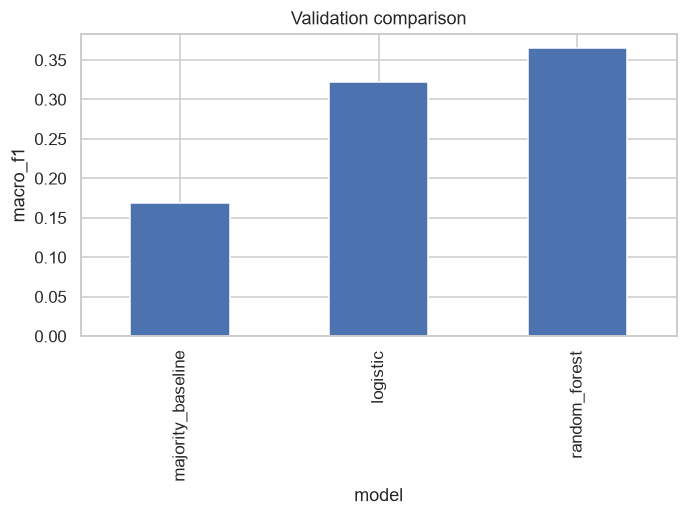

,selected_model,baseline
accuracy,0.353234,0.338308
balanced_accuracy,0.353957,0.333333
macro_f1,0.351202,0.168525


,precision,recall,f1-score,support
female,0.333333,0.328358,0.330827,67.000000
male,0.350877,0.294118,0.320000,68.000000
none,0.371795,0.439394,0.402778,66.000000
accuracy,0.353234,0.353234,0.353234,0.353234
macro avg,0.352002,0.353957,0.351202,201.000000
weighted avg,0.351898,0.353234,0.350790,201.000000


,female,male,none
female,22,21,24
male,23,20,25
none,21,16,29


In [22]:
score = 'rmse' if TASK == 'flights' else ('macro_f1' if TASK == 'classification' else 'ndcg_at_3')
ax = candidates.set_index('model')[score].plot.bar(title='Validation comparison')
ax.set_ylabel(score)
plt.tight_layout()
image_buffer = BytesIO()
ax.figure.savefig(image_buffer, format='png', dpi=110, bbox_inches='tight')
display(Image(data=image_buffer.getvalue()))
plt.close(ax.figure)
display(pd.DataFrame({'selected_model': report['test_metrics'], 'baseline': report['test_baseline']}))
if TASK == 'classification':
    display(pd.DataFrame(report['classification_report']).T)
    display(pd.DataFrame(report['confusion_matrix'], index=report['labels'], columns=report['labels']))
if TASK == 'flights':
    display(pd.DataFrame(report['error_slices']).sort_values('mae', ascending=False).head(10))

### Evaluation, business meaning and model choice
Macro F1 gives each source label equal weight; balanced accuracy averages per-class recall. A majority baseline prevents misleading claims based only on raw accuracy.

The table shows whether personalization or a learned classifier actually improves on its baseline. A weak or negative result must stay in the report. Very high flight accuracy on this constrained historical catalogue does not imply comparable live-market accuracy. Analyze route/cabin slices and report their sample sizes. For classification, inspect each label rather than implying aggregate accuracy applies equally to everyone. Recommendation evaluation concerns held-out observed bookings, not user satisfaction.

### Explainability
Use the following held-out permutation check for predictive models; it measures score changes under input permutation and may understate correlated features. For recommendations, inspect the actual popularity/history signals. Neither explanation establishes causality.

In [23]:
bundle, manifest = load_bundle(TASK)
if TASK != 'hotels':
    from sklearn.inspection import permutation_importance
    feature_names = ['company', 'age'] if TASK == 'classification' else ['from', 'to', 'flightType', 'agency', 'time', 'distance', 'date']
    sample = test.sample(min(500, len(test)), random_state=42)
    target = sample.gender if TASK == 'classification' else sample.price
    scoring = 'f1_macro' if TASK == 'classification' else 'neg_mean_absolute_error'
    explanation = permutation_importance(bundle['pipeline'], sample[feature_names], target, n_repeats=3, random_state=42, scoring=scoring)
    display(pd.DataFrame({'feature': feature_names, 'importance': explanation.importances_mean}).sort_values('importance', ascending=False))
else:
    from voyage.recommendation import recommend
    display(pd.DataFrame(recommend(bundle, user_code=0, k=3)))

,feature,importance
0,company,0.025362
1,age,-0.026504


## 8. Future Work and Deployment Artifact
The complete pipeline or recommendation bundle is saved as joblib with a SHA-256 manifest. A separate promotion operation only approves passing candidates; failed candidates preserve the current release. The Flask app loads the exact same artifact at startup. MLflow records the experiment and bundle. Kubernetes/Jenkins deployment evidence is maintained separately and must not be inferred merely from a configuration file.

In [24]:
print('Verified version:', manifest['version'])
print('Artifact:', manifest['artifact'])
print('Checksum:', manifest['sha256'])
if TASK != 'hotels':
    sample = test.head(3)
    display(bundle['pipeline'].predict(sample[feature_names]))
else:
    display(pd.DataFrame(recommend(bundle, user_code=999999, k=3)))

Verified version: 54a8c7993c9c4b8ea0340cf8d54103dc
Artifact: releases/classification/54a8c7993c9c4b8ea0340cf8d54103dc/model.joblib
Checksum: bbebc163ecdf52d64caddfa642c93a181abca6a5fe0ae388d29b9b7e02e337ec


array(['none', 'male', 'male'], dtype=object)

# Conclusion
This notebook connects data understanding, partition design, modeling, evaluation and a reproducible serving artifact. Read the measured comparison above before claiming any improvement. Future work includes newer independently sourced records, better documented field semantics, stronger temporal robustness checks and actual outcome feedback. Recommendation improvements require a richer catalogue. Classification remains an educational source-label benchmark with limited business relevance.

The repository contains the API, Streamlit application, infrastructure and workflow code. The submission documentation must distinguish stages that ran successfully from stages still awaiting hosting or account setup.